# Online Stochastic Matchings: Stability on Hypergraphs

This is the companion notebook of the paper *Online Stochastic Matchings: Stability on Hypergraphs*.

It covers the numerical claims of the paper, focusing on the candy hypergraph:

1. **The characterization of stability.** `model.stabilizable` decides any $(G,\lambda)$; `model.maximin`
   gives the witness flow $\mu$; `model.incidence` gives the matrix.
2. **The candy's closed-form stability region**, checked against `model.stabilizable`.
3. **Regular greedy ML vs. VQML** on the candy $\alpha$-family (the paper's figure).
4. **The provable greedy-instability thresholds**:
   $\alpha_{\mathrm{c}}=\tfrac23(\sqrt{10}-3)\approx 0.108$ for every greedy policy, clairvoyant
   ones included, and
   $\alpha_{\mathrm{g}}=(1+\sqrt{17})/12\approx 0.427$ for the non-anticipative ones, with the
   bounds on the hyperedge rate behind them.
5. **Accessibility and tie-breaking of the virtual chain**: proof-level combinatorics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import multiprocess as mp
import stochastic_matching as sm
from stochastic_matching import XP, Iterator, evaluate

print("stochastic_matching:", sm.__version__)
np.set_printoptions(precision=4, suppress=True)

stochastic_matching: 0.4.0


First, recall the candy structure: two triangles bridged by a hyperedge that includes a seventh node:

In [2]:
candy = sm.HyperPaddle()
print("candy incidence A (from model.incidence):")
print(np.asarray(candy.incidence), "\n")
candy.show_graph()

candy incidence A (from model.incidence):
[[1 1 0 0 0 0 0]
 [1 0 1 0 0 0 0]
 [0 1 1 0 0 0 1]
 [0 0 0 0 0 0 1]
 [0 0 0 1 1 0 1]
 [0 0 0 1 0 1 0]
 [0 0 0 0 1 1 0]] 



## Characterization of stability

The package decides stabilizability directly: `model.stabilizable` is `True` iff the maximin
conservation flow is strictly positive **and** the incidence matrix is surjective, i.e.
conditions (iii)/(iv) of the main theorem. When stabilizable, `model.maximin` *is* a positive
witness $\mu$ with $A\mu=\lambda$; when not, either the flow has a non-positive coordinate
(the cone is left) or $A$ is rank-deficient.

> Note: The dual *certificate* $y$ of condition (ii) is stated in the paper; the package works directly with the primal witness.

We will use the `report` function to observe a few cases.

In [3]:
def report(name, model):
    A = np.asarray(model.incidence)
    mu = np.asarray(model.maximin)
    rank, n = np.linalg.matrix_rank(A), A.shape[0]
    print(f"{name}")
    print(f"  stabilizable = {model.stabilizable}   "
          f"(rank A = {rank} of {n}; maximin min = {mu.min():.3f})")
    print(f"  maximin flow mu = {mu.round(4)}")

In [4]:
candy.rates = [1, 1, 0.9, 0.3, 0.9, 1, 1]
report("candy, alpha-family (alpha=0.3): lambda=(1,1,3a,a,3a,1,1)", candy)
candy.show_flow()

candy, alpha-family (alpha=0.3): lambda=(1,1,3a,a,3a,1,1)
  stabilizable = True   (rank A = 7 of 7; maximin min = 0.300)
  maximin flow mu = [0.7 0.3 0.3 0.3 0.3 0.7 0.3]


In [5]:
candy.rates = [1, 1, 1, 5, 1, 1, 1]
report("candy, center overloaded λ_4=5", candy)
candy.show_flow()

candy, center overloaded λ_4=5
  stabilizable = False   (rank A = 7 of 7; maximin min = -2.000)
  maximin flow mu = [ 3. -2. -2. -2. -2.  3.  5.]


In [6]:
model = sm.Model(incidence=[[0, 1, 1, 0], [0, 0, 1, 1], [1, 1, 1, 1]], rates=[1, 1, 2]) 
report("rem:wall degenerate (stabilizable; every basic solution degenerate)", model)
model.show_kernel(disp_flow=True)

rem:wall degenerate (stabilizable; every basic solution degenerate)
  stabilizable = True   (rank A = 3 of 3; maximin min = 0.500)
  maximin flow mu = [0.5 0.5 0.5 0.5]


In [7]:
model = sm.Model(incidence=[[1], [1], [1]], rates=[1, 1, 1])
report("Moyal single 3-hyperedge {1,2,3} (rank 1 < 3)", model)
model.show_kernel(disp_flow=True)

Moyal single 3-hyperedge {1,2,3} (rank 1 < 3)
  stabilizable = False   (rank A = 1 of 3; maximin min = 1.000)
  maximin flow mu = [1.]


In [8]:
model = sm.Model(incidence=[[1, 0], [1, 0], [1, 1], [0, 1]], rates=[1, 1, 2, 1])
report("Moyal RM21 Prop-4 flavor: {1,2,3}+{3,4}, classes 1,2 degree one", model)
model.show_kernel(disp_flow=True)

Moyal RM21 Prop-4 flavor: {1,2,3}+{3,4}, classes 1,2 degree one
  stabilizable = False   (rank A = 2 of 4; maximin min = 1.000)
  maximin flow mu = [1. 1.]


## The candy's closed-form stability region

For the candy $A$ is square and invertible, so stabilizability $\iff$ the unique solution of
$A\mu=\lambda$ is strictly positive, which solves to
$$|\lambda_1-\lambda_2| < \lambda_3-\lambda_4 < \lambda_1+\lambda_2 \quad\text{and}\quad
  |\lambda_7-\lambda_6| < \lambda_5-\lambda_4 < \lambda_6+\lambda_7.$$

Recipe for the formula above:
- The 3-edge must be $\lambda_4$, leaving $\bar{\lambda_3}=\lambda_3-\lambda_4$ and $\bar{\lambda_5}=\lambda_5-\lambda_4$ for nodes 3 and 5.
- That leaves the triangles $\lambda_1$, $\lambda_2$, $\bar{\lambda_3}$, and $\lambda_6$, $\lambda_7$, $\bar{\lambda_5}$, which must uphold the triangular inequality.
- Triangular inequality for $a$, $b$, $c$: $|b-c|<a<b+c$.
  
One can check this closed form against `model.stabilizable` on random
rate vectors.

In [9]:
def candy_closed_form(lam):
    l1, l2, l3, l4, l5, l6, l7 = lam
    return (abs(l1 - l2) < l3 - l4 < l1 + l2) and (abs(l7 - l6) < l5 - l4 < l6 + l7)

rng = np.random.default_rng(0)
mism = 0
for _ in range(20000):
    lam = rng.uniform(0.2, 3.0, size=7)
    if candy_closed_form(lam) != sm.HyperPaddle(rates=list(lam)).stabilizable:
        mism += 1
print(f"closed form vs model.stabilizable over 20000 random rate vectors: {mism} mismatches")

closed form vs model.stabilizable over 20000 random rate vectors: 0 mismatches


## Greedy Match-the-longest (ML) vs. VQML on the candy $\alpha$-family

$\lambda^{(\alpha)}=(1,1,3\alpha,\alpha,3\alpha,1,1)$ is stabilizable for every
$\alpha\in(0,1)$, with the five *inner* edges having rate $\alpha$ and the two outer edges having rate $1-\alpha$.

Note that the extremal values, 0 and 1, yield an unstable problem (the support of the unique solution is not surjective).

Greedy match-the-longest lets the central queue explode for $\alpha < \alpha_{\mathrm{ML}}$, while VQML stays stable in $(0, 1)$.

Step #1: estimate $\alpha_{\mathrm{ML}}$.

A fixed horizon is not enough near the threshold: just below it, match-the-longest is
unstable but its central queue grows slowly, and a run of $10^7$ arrivals can end below any
reasonable cap. We use a growth test instead. Each $\alpha$ is run twice with the same seed,
for $10^7$ and $16 \cdot 10^7$ arrivals; the run is declared unstable if it hits the queue cap,
or if the mean central queue $\overline{Q_4}$ more than quadruples between the two horizons
(linear growth multiplies it by about 16, a stable run by about 1).

In [10]:
steps_done = 10_000_000
common = {'n_steps': steps_done, 'seed': 12, 'max_queue': 10_000}

def candy_at(alpha):
    return sm.HyperPaddle(rates=[1.0, 1.0, 3 * alpha, alpha, 3 * alpha, 1.0, 1.0])

In [11]:
def ml_unstable(alpha, short=10_000_000, factor=16, seed=12, cap=100_000):
    # Runs in pool workers: keep it self-contained.
    import stochastic_matching as sm
    means = []
    for n in (short, factor * short):
        model = sm.HyperPaddle(rates=[1.0, 1.0, 3 * alpha, alpha, 3 * alpha, 1.0, 1.0])
        sim = sm.Longest(model, n_steps=n, seed=seed, max_queue=cap)
        sim.run()
        if sim.logs.steps_done < n:
            return True
        means.append(float(sim.avg_queues[3]))
    return means[1] > 4 * means[0]

αmin = 0.0
αmax = 1.0
ϵ = .001
with mp.Pool() as pool:
    span = pool._processes
    while αmax - αmin > ϵ:
        alphas = [αmin + (αmax - αmin)*i/(span+1) for i in range(1, span+1)]
        unstable = pool.map(ml_unstable, alphas)
        if not unstable[0]:
            αmax = alphas[0]
        else:
            for i in range(1, span):
                if not unstable[i]:
                    αmin, αmax = alphas[i-1], alphas[i]
                    break
            else:
                αmin = alphas[-1]
    αML = (αmin+αmax)/2
αML

0.45216771829839203

We then sweep $\alpha$.

We plot two metrics side by side: the mean central queue $\overline{Q_4}$ (the coordinate the
instability proof bounds, and the paper's figure) and the package's built-in `delay` (mean
waiting time by Little's law, $\sum_i\overline{Q_i}/\Lambda$). 

Both show the same thing on the left: greedy blows up as $\alpha\to \alpha_{\mathrm{ML}}$ while VQML goes to 0, so the separation does not hinge on singling out node~4. 

At large $\alpha$, delay and $\overline{Q_4}$ differ: as $\alpha \to 1$ the backlog sits in the
bridge nodes 3 and 5, not in the central node 4 nor in the outer nodes. At $\alpha = 1$ the
certificate $y = e_3 - e_1 - e_2 - e_4$ (and its mirror image) shows that the problem is not
stabilizable, and it charges node 3.

Also note that for delay and large $\alpha$, the curves cross: VQML carries slightly more global delay than
greedy. It is understandable, since VQML is a maximally *stable* witness through a reservation mechanism, not a delay optimizer.

In [12]:
# Metrics run in pool workers (shipped by value via dill), so keep them
# self-contained: no module globals. Node 4 = 0-based index 3.
def central_queue(simu):
    return float(simu.avg_queues[3])

alphas = [i/100 for i in range(1, 100)]
alphas2 = [i/100 for i in range(int(αML*100)+1, 100)]


xp = XP('ML', simulator='longest',
        iterator=Iterator('model', alphas2, name='alpha', process=candy_at), **common)
xp += XP('VQML', simulator='virtual_queue',
         iterator=Iterator('model', alphas, name='alpha', process=candy_at), **common)

with mp.Pool() as pool:
    res = evaluate(xp, ['steps_done', central_queue, 'delay'], pool)

  0%|          | 0/153 [00:00<?, ?it/s]

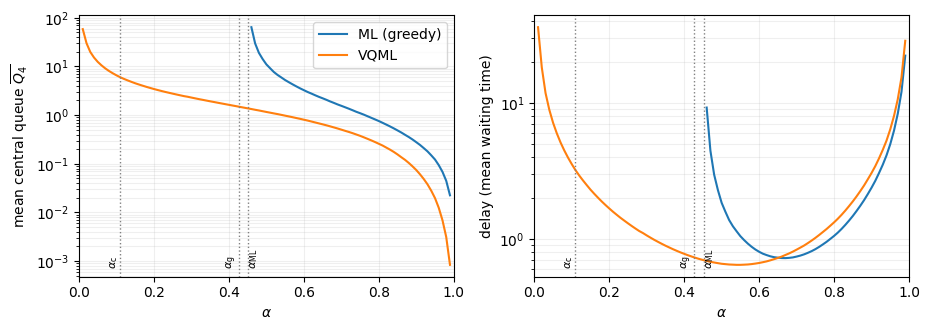

In [13]:
# Instability is proven below αc for every greedy policy, clairvoyant ones included, and
# below αg for the non-anticipative ones (next section); αML is the empirical threshold
# of ML found above.
αc = 2 * (10 ** 0.5 - 3) / 3
αg = (1 + 17 ** 0.5) / 12

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4), sharex=True)
panels = [('central_queue', r'mean central queue $\overline{Q_4}$'),
          ('delay', r'delay (mean waiting time)')]


for ax, (key, ylabel) in zip(axes, panels):
    # yml, yvq = np.array(ml[key]), np.array(vq[key])
    ax.semilogy(res['ML']['alpha'], res['ML'][key], ms=4, label='ML (greedy)')
    ax.semilogy(res['VQML']['alpha'], res['VQML'][key], ms=5, label='VQML')
    for x, name, ha in [(αc, r'$\alpha_{\mathrm{c}}$', 'right'), (αg, r'$\alpha_{\mathrm{g}}$', 'right'),
                        (αML, r'$\alpha_{\mathrm{ML}}$', 'left')]:
        ax.axvline(x, color='gray', ls=':', lw=1)
        ax.text(x, 0.03, name, rotation=90, va='bottom', ha=ha, fontsize=8,
                transform=ax.get_xaxis_transform())
    ax.set_xlabel(r'$\alpha$'); ax.set_ylabel(ylabel)
    ax.set_xlim(0, 1); ax.grid(True, which='both', alpha=0.2)
axes[0].legend()
plt.tight_layout(); plt.show()

## The provable greedy-instability thresholds

Class 4 leaves the system only through the hyperedge $\{3,4,5\}$, so a greedy policy is
unstable as soon as the hyperedge fires at a rate $r_h$ below $\lambda_4=\alpha$ (rates per unit
of time). The paper bounds $r_h$ in two ways.

- **Every greedy policy**, even a clairvoyant one, aware of future arrivals:
  $r_h\le\tfrac94\alpha^2(4+\alpha)$, which is below $\alpha$ for
  $\alpha<\alpha_{\mathrm{c}}=\tfrac23(\sqrt{10}-3)\approx 0.108$. The bridge queue $Q_3$ is
  dominated by a walk that the class-3 arrivals push up and the arrivals of classes 1 and 2
  push down, so that $Q_3>0$ at a fraction of the epochs at most $3\alpha/2$; likewise for
  $Q_5$, and the two walks are independent in the long run.
- **Non-anticipative greedy policies**, such as match-the-longest:
  $r_h\le 27\alpha^3/(2+3\alpha+9\alpha^2)$, which is below $\alpha$ for
  $\alpha<\alpha_{\mathrm{g}}=(1+\sqrt{17})/12\approx 0.427$. The proof weighs each triangle,
  and uses the stocks of the outer classes, which the domination ignores.

We run match-the-longest on both sides of its empirical threshold $\alpha_{\mathrm{ML}}$ and
compare its hyperedge rate with the two bounds and with $\lambda_4$. Below
$\alpha_{\mathrm{ML}}$ the central queue grows linearly, hence the large queue cap. The measured
rate stays within a few percent of the non-anticipative bound. For small $\alpha$ the bound
is almost attained, and a single run may fall on either side of it, within the standard
deviation shown (that of a Poisson count of the firings). Above $\alpha_{\mathrm{ML}}$ the run is
stable and the hyperedge fires at rate $\lambda_4$.

In [14]:
# Self-contained metrics (run in pool workers). Bridge = node 3 (0-based 2),
# hyperedge {3,4,5} = edge index 6.
def p_bridge(simu):                      # fraction of the epochs with Q_bridge > 0
    return 1.0 - simu.logs.queue_log[2, 0] / simu.logs.steps_done

def rate_h_time(simu):                   # hyperedge firings per unit time
    return float(simu.logs.traffic[6] / simu.logs.steps_done * sum(simu.model.rates))

def firings(simu):                       # number of hyperedge firings
    return int(simu.logs.traffic[6])

def bound_all(a):                        # every greedy policy
    return 9 * a**2 * (4 + a) / 4

def bound_na(a):                         # non-anticipative greedy policies
    return 27 * a**3 / (2 + 3 * a + 9 * a**2)

n4 = 10_000_000
xp4 = XP('greedy', simulator='longest', model=None, n_steps=n4, seed=1, max_queue=n4 // 10,
         iterator=Iterator('model', [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6], name='alpha', process=candy_at))
with mp.Pool() as pool:
    r4 = evaluate(xp4, ['steps_done', p_bridge, rate_h_time, firings], pool)['greedy']

print(f"alpha_c = {αc:.4f};  alpha_g = {αg:.4f};  simulated ML threshold alpha_ML = {αML:.3f}\n")
print("alpha   r_h of ML (+/- 1 s.d.)   bound, non-anticipative   bound, every greedy   lambda_4   "
      "P(Q3>0)   3*alpha/2")
for a, done, pb, rh, nh in zip(r4['alpha'], r4['steps_done'], r4['p_bridge'],
                               r4['rate_h_time'], r4['firings']):
    assert done == n4                    # the queue cap was not reached
    print(f"{a:5.2f}   {rh:.5f} +/- {rh / nh ** 0.5:.5f}      {bound_na(a):.5f}                   "
          f"{bound_all(a):.5f}               {a:.2f}       {pb:.4f}    {1.5 * a:.3f}")

  0%|          | 0/7 [00:00<?, ?it/s]

alpha_c = 0.1082;  alpha_g = 0.4269;  simulated ML threshold alpha_ML = 0.452

alpha   r_h of ML (+/- 1 s.d.)   bound, non-anticipative   bound, every greedy   lambda_4   P(Q3>0)   3*alpha/2
 0.05   0.00158 +/- 0.00003      0.00155                   0.02278               0.05       0.0052    0.075
 0.10   0.01121 +/- 0.00007      0.01130                   0.09225               0.10       0.0183    0.150
 0.20   0.07088 +/- 0.00020      0.07297                   0.37800               0.20       0.0585    0.300
 0.30   0.18755 +/- 0.00034      0.19650                   0.87075               0.30       0.1043    0.450
 0.40   0.35226 +/- 0.00049      0.37241                   1.58400               0.40       0.1468    0.600
 0.50   0.50018 +/- 0.00061      0.58696                   2.53125               0.50       0.2167    0.750
 0.60   0.59987 +/- 0.00070      0.82841                   3.72600               0.60       0.3388    0.900


## Accessibility and tie-breaking of the virtual chain

Two structural facts about the signed virtual queue $Q$. These are *proof-level* combinatorics
(a custom adversarial tie-break rule, and a deterministic steering word) that the package's
`virtual_queue` simulator does not expose as knobs, so we check them directly with numpy.

**(a) The $I_2$ trap (tie-breaking remark).** Take $A=I_2$ (two mono-edges), $\lambda=(1,1)$,
and a legal *deterministic* maximizer rule that violates the idle clause (among maximizers,
prefer $2e_1, e_1, 2e_2, 0, e_2, e_1+e_2$). The set reachable from $0$ then has **9** states,
with $0$ visited exactly once and a **7**-state absorbing class. So the idle clause is what the
accessibility argument needs.

**(b) Steering to $0$ (accessibility lemma).** Under the canonical idle clause, the Appendix-A
steering drives $Q$ to $0$ from every state within $\lVert q\rVert_1 + 2 a_{\max} V(q)$. We run
it from many mixed-sign start states over a suite of incidence matrices (from the package where
available).

In [15]:
import itertools

# (a) adversarial I2 tie-break trap
A_I2 = np.eye(2, dtype=int)
feas = [s for s in itertools.product(range(3), repeat=2) if sum(s) <= 2]
pref = [(2, 0), (1, 0), (0, 2), (0, 0), (0, 1), (1, 1)]   # most preferred maximizer first

def i2_rule(q):
    scores = {s: int(np.array(q) @ (A_I2 @ np.array(s))) for s in feas}
    best = max(scores.values())
    cand = [s for s in feas if scores[s] == best]
    return next(s for s in pref if s in cand)

start = (0, 0); seen = {start}; frontier = [start]; edges = {}
while frontier:
    q = frontier.pop(); s = np.array(i2_rule(q)); succ = set()
    for a in ([1, 0], [0, 1]):
        qp = tuple(np.array(q) + np.array(a) - (A_I2 @ s)); succ.add(qp)
        if qp not in seen: seen.add(qp); frontier.append(qp)
    edges[q] = succ

def freach(src):
    acc = {src}; st = [src]
    while st:
        for v in edges.get(st.pop(), ()):
            if v not in acc: acc.add(v); st.append(v)
    return acc

reach = {u: freach(u) for u in seen}
sccs = []; done = set()
for u in seen:
    if u in done: continue
    comp = {v for v in seen if v in reach[u] and u in reach[v]}
    sccs.append(comp); done |= comp
bottom = sorted(len(c) for c in sccs if all(edges[u] <= c for u in c))
reenter = start in {v for x in edges[start] for v in reach[x]}
print(f"(a) I2 trap: reachable from 0 = {len(seen)} (paper 9); "
      f"0 re-enterable = {reenter} (paper False); absorbing SCC sizes = {bottom} (paper [7])")

# (b) steering to 0 under the canonical idle clause
def steer_to_zero(A, q0):
    A = np.asarray(A, int); n, m = A.shape
    a_max = max(int(A[:, k].sum()) for k in range(m))
    q = np.array(q0, int)
    bound = int(np.abs(q).sum()) + 2 * a_max * int(np.maximum(q, 0).sum())
    steps = 0
    while np.any(q != 0):
        if steps > bound: return False, steps, bound
        scores = A.T @ q
        if scores.max() <= 0:                                  # idle: drain a negative coord
            q = q + np.eye(n, dtype=int)[int(np.argmin(q))]
        else:                                                  # active: s = 2 e_kstar
            r = q - 2 * A[:, int(np.argmax(scores))]
            neg = np.where(r <= -1)[0]
            q = r + np.eye(n, dtype=int)[int(neg[0]) if neg.size else 0]
        steps += 1
    return True, steps, bound

suite = {
    "I2": A_I2,
    "candy": np.asarray(sm.HyperPaddle(rates=[1, 1, 1, 1, 1, 1, 1]).incidence),   # incidence from package
    "rem:wall": np.array([[0, 1, 1, 0], [0, 0, 1, 1], [1, 1, 1, 1]]),
    "Moyal {1,2,3}": np.array([[1], [1], [1]]),
    "Moyal {1,2,3}+{3,4}": np.array([[1, 0], [1, 0], [1, 1], [0, 1]]),
}
rng2 = np.random.default_rng(0); total = good = 0
for name, A in suite.items():
    for _ in range(200):
        reached, steps, bound = steer_to_zero(A, rng2.integers(-4, 6, size=A.shape[0]))
        total += 1; good += int(reached and steps <= bound)
print(f"(b) steering: {good}/{total} start states over the suite reach 0 within the bound")

(a) I2 trap: reachable from 0 = 9 (paper 9); 0 re-enterable = False (paper False); absorbing SCC sizes = [7] (paper [7])
(b) steering: 1000/1000 start states over the suite reach 0 within the bound
